# AeroScapes Aerial Semantic Segmentation: All-in-One Standalone Experiment
### Model A (Baseline: No Skips) vs. Model B (Controlled: Skip Fusion)

**100% Self-Contained Notebook**: You do **NOT** need to upload `requirements.txt`, `config.yaml`, or any Python scripts. Everything is defined directly inside this single notebook!

- **Hardware**: Google Colab Free-Tier NVIDIA Tesla T4 GPU (16GB VRAM)
- **Dataset**: AeroScapes (3,269 drone-view 720p images, 12 classes)
- **Model A**: Compact 4-stage encoder-decoder, bottleneck only, **no skip connections** (6.46M params)
- **Model B**: Controlled change with **skip fusion via concatenation** (7.24M params)
- **Controlled Environment**: Identical seed (42), resolution (384x256), batch size (8), optimizer (AdamW), LR schedule (Cosine with warmup), and loss function.

## 1. Setup & GPU Verification
Colab comes with PyTorch, Torchvision, NumPy, Matplotlib, and SciPy pre-installed. We only install lightweight helper tools (`gdown` and `torchinfo`).

In [9]:
# Install minimal helper packages directly
!pip install -q gdown torchinfo

# Check GPU accelerator
import torch
print(f'PyTorch: {torch.__version__}')
print(f'CUDA Available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')
else:
    print('WARNING: GPU not active! Go to Runtime > Change runtime type > T4 GPU.')

# Mount Google Drive for persistent checkpoints (optional but recommended)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_CKPT_DIR = '/content/drive/MyDrive/aeroscapes_checkpoints'
    import os
    os.makedirs(DRIVE_CKPT_DIR, exist_ok=True)
    print(f'Drive backup active at: {DRIVE_CKPT_DIR}')
except Exception:
    DRIVE_CKPT_DIR = None
    print('Running locally without Google Drive mount.')

PyTorch: 2.14.1+cu130
CUDA Available: True
GPU: Tesla T4
VRAM: 15.64 GB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive backup active at: /content/drive/MyDrive/aeroscapes_checkpoints


## 2. Obtain AeroScapes Dataset
Downloads the dataset package using the authors' official Google Drive link (`1WmXcm0IamIA0QPpyxRfWKnicxZByA60v`) and unzips it.

In [10]:
import os, zipfile, glob
import gdown

# Helper to check if images exist
def has_images(path):
    if not os.path.exists(path): return False
    for root, _, files in os.walk(path):
        if any(f.endswith('.jpg') for f in files):
            return True
    return False

if not has_images('.'):
    # 1. Check for any uploaded zip files in Colab or Google Drive
    candidate_zips = glob.glob('*.zip') + glob.glob('/content/*.zip') + glob.glob('/content/drive/MyDrive/*aeroscapes*.zip') + glob.glob('/content/drive/MyDrive/*Dataset*.zip')

    if candidate_zips:
        zip_to_extract = candidate_zips[0]
        print(f'Found local archive: {zip_to_extract}. Extracting...')
        with zipfile.ZipFile(zip_to_extract, 'r') as zf:
            zf.extractall('Dataset')
        print('Extraction complete!')
    else:
        print('Downloading AeroScapes dataset archive (~1.5 GB)...')
        # Official author Google Drive ID with fuzzy flag to bypass virus scan warning
        url = 'https://drive.google.com/uc?id=1WmXcm0IamIA0QPpyxRfWKnicxZByA60v'
        gdown.download(url, 'aeroscapes.zip', quiet=False, fuzzy=True)
        if os.path.exists('aeroscapes.zip') and os.path.getsize('aeroscapes.zip') > 1000000:
            print('Extracting downloaded archive...')
            with zipfile.ZipFile('aeroscapes.zip', 'r') as zf:
                zf.extractall('Dataset')
            print('Extraction complete!')
        else:
            print('WARNING: Automated download failed.')
            print('Manual Step: Upload your Dataset folder (or zip) to the Colab files panel on the left!')
else:
    print('Dataset already extracted on disk. Ready!')

Dataset already extracted on disk. Ready!


In [13]:
!unzip -q /content/Dataset.zip -d /content/

## 3. Dataset Preprocessing, Splits Generation & Verification
- Verifies 1-to-1 pairing of all 3,269 images and masks.
- Decodes Supervisely JSON annotations into fast, indexed single-channel PNG masks (`0..11`).
- Generates a fixed 70/15/15 train/val/test split (`splits/train.txt`, `splits/val.txt`, `splits/test.txt`).
- Prints class frequencies showing the real drone-view class imbalance.

In [14]:
import json, zlib, base64, io, random, os
from collections import Counter
import numpy as np
from PIL import Image
from tqdm import tqdm

CLASS_NAME_TO_ID = {
    'background': 0, 'person': 1, 'bike': 2, 'car': 3, 'drone': 4,
    'boat': 5, 'animal': 6, 'obstacle': 7, 'construction': 8,
    'vegetation': 9, 'road': 10, 'sky': 11
}
CLASS_ID_TO_NAME = {v: k for k, v in CLASS_NAME_TO_ID.items()}
PRIORITY_ORDER = ['background', 'sky', 'vegetation', 'road', 'construction',
                  'obstacle', 'boat', 'car', 'animal', 'drone', 'bike', 'person']

def decode_supervisely_json_to_mask(json_path, height=720, width=1280):
    with open(json_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    h = data.get('size', {}).get('height', height)
    w = data.get('size', {}).get('width', width)
    mask = np.zeros((h, w), dtype=np.uint8)
    objects = data.get('objects', [])
    sorted_objs = sorted(objects, key=lambda obj: PRIORITY_ORDER.index(obj['classTitle']) if obj.get('classTitle') in PRIORITY_ORDER else 99)
    for obj in sorted_objs:
        cname = obj.get('classTitle')
        if cname not in CLASS_NAME_TO_ID or not obj.get('bitmap'):
            continue
        cid = CLASS_NAME_TO_ID[cname]
        origin = obj['bitmap'].get('origin')
        b64_str = obj['bitmap'].get('data')
        if not origin or not b64_str:
            continue
        x0, y0 = origin[0], origin[1]
        decompressed = zlib.decompress(base64.b64decode(b64_str))
        bmp_arr = np.array(Image.open(io.BytesIO(decompressed)))
        sub_mask = bmp_arr[:, :, 3] > 0 if bmp_arr.ndim == 3 and bmp_arr.shape[2] >= 4 else (bmp_arr > 0)
        bh, bw = sub_mask.shape[:2]
        y1, x1 = min(y0 + bh, h), min(x0 + bw, w)
        sub_h, sub_w = y1 - y0, x1 - x0
        if sub_h > 0 and sub_w > 0:
            patch = mask[y0:y1, x0:x1]
            patch[sub_mask[:sub_h, :sub_w]] = cid
            mask[y0:y1, x0:x1] = patch
    return mask

# 1. Recursively find image and annotation pairs anywhere in Colab
paired_samples = []
print('Scanning filesystem for AeroScapes images and annotations...')
for root, dirs, files in os.walk('.'):
    if any(p in root for p in ['preprocessed_masks', 'checkpoints', '.git', '.cache', '__pycache__', '.ipynb_checkpoints']):
        continue
    jpg_files = [f for f in files if f.endswith('.jpg')]
    if jpg_files:
        parent = os.path.dirname(root)
        ann_dir_cand = os.path.join(parent, 'ann')
        mask_dir_cand = os.path.join(parent, 'SegmentationClass')
        for j in jpg_files:
            stem = os.path.splitext(j)[0]
            img_path = os.path.join(root, j)
            json_path = os.path.join(ann_dir_cand, j + '.json')
            png_path = os.path.join(mask_dir_cand, stem + '.png')
            if os.path.exists(json_path):
                paired_samples.append((stem, img_path, json_path, 'json'))
            elif os.path.exists(png_path):
                paired_samples.append((stem, img_path, png_path, 'png'))

print(f'Total paired samples discovered: {len(paired_samples)}')
if len(paired_samples) == 0:
    raise FileNotFoundError(
        'ERROR: 0 paired images found! Please upload your Dataset folder/zip to Colab '
        'or run the download cell above.'
    )

# 2. Deduplicate and create seeded 70/15/15 splits
os.makedirs('splits', exist_ok=True)
unique_samples = {s[0]: s for s in paired_samples}
all_ids = sorted(list(unique_samples.keys()))
rng = np.random.RandomState(42)
shuffled = rng.permutation(len(all_ids))
n_total = len(all_ids)
n_tr, n_val = int(n_total * 0.70), int(n_total * 0.15)
splits = {
    'train': [all_ids[i] for i in shuffled[:n_tr]],
    'val': [all_ids[i] for i in shuffled[n_tr:n_tr+n_val]],
    'test': [all_ids[i] for i in shuffled[n_tr+n_val:]]
}
for s_name, ids in splits.items():
    with open(f'splits/{s_name}.txt', 'w') as f:
        f.write('\n'.join(sorted(ids)) + '\n')
    print(f'Saved split {s_name}: {len(ids)} images')

# 3. Decode masks into single-channel PNGs
os.makedirs('Dataset/preprocessed_masks', exist_ok=True)
print('\nDecoding masks into single-channel PNGs...')
pixel_counts = Counter()
for img_id, img_p, ann_p, kind in tqdm(unique_samples.values()):
    dest_png = f'Dataset/preprocessed_masks/{img_id}.png'
    if os.path.exists(dest_png):
        m = np.array(Image.open(dest_png))
    else:
        if kind == 'json':
            m = decode_supervisely_json_to_mask(ann_p)
        else:
            m = np.array(Image.open(ann_p))
        Image.fromarray(m, mode='L').save(dest_png)
    vals, counts = np.unique(m, return_counts=True)
    for v, c in zip(vals, counts):
        pixel_counts[int(v)] += int(c)

tot_px = sum(pixel_counts.values())
print(f'\nTotal Pixels Analyzed: {tot_px:,}')
print('=== Empirical Class Pixel Frequencies ===')
for cid in range(12):
    cnt = pixel_counts[cid]
    freq = (cnt / tot_px * 100.0) if tot_px > 0 else 0.0
    print(f'Class {cid:2d} ({CLASS_ID_TO_NAME[cid]:12s}): {cnt:12,d} px ({freq:6.2f}%)')

Scanning filesystem for AeroScapes images and annotations...
Total paired samples discovered: 3269
Saved split train: 2288 images
Saved split val: 490 images
Saved split test: 491 images

Decoding masks into single-channel PNGs...


  0%|          | 0/3269 [00:00<?, ?it/s]/tmp/ipykernel_1146/2731340558.py:105: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(m, mode='L').save(dest_png)
100%|██████████| 3269/3269 [01:47<00:00, 30.43it/s]


Total Pixels Analyzed: 3,012,710,400
=== Empirical Class Pixel Frequencies ===
Class  0 (background  ):  696,388,200 px ( 23.12%)
Class  1 (person      ):   12,114,423 px (  0.40%)
Class  2 (bike        ):    1,596,917 px (  0.05%)
Class  3 (car         ):   11,114,500 px (  0.37%)
Class  4 (drone       ):      877,424 px (  0.03%)
Class  5 (boat        ):      653,619 px (  0.02%)
Class  6 (animal      ):    2,524,067 px (  0.08%)
Class  7 (obstacle    ):   16,946,045 px (  0.56%)
Class  8 (construction):  133,909,912 px (  4.44%)
Class  9 (vegetation  ): 1,117,021,451 px ( 37.08%)
Class 10 (road        ):  881,708,346 px ( 29.27%)
Class 11 (sky         ):  137,855,496 px (  4.58%)


## 4. PyTorch Dataset, DataLoaders & Aligned Transforms
- Resizes images to `384x256` (Bilinear for RGB, Nearest-Neighbor for mask).
- ImageNet normalization: $\mu=[0.485, 0.456, 0.406]$, $\sigma=[0.229, 0.224, 0.225]$.
- Spatial augmentations (Horizontal Flip, Scale-Crop) are applied identically to image and mask.
- Color jitter is applied only to the RGB image.

In [15]:
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader

class AlignedSegmentationTransform:
    def __init__(self, height=256, width=384, is_train=True):
        self.height, self.width, self.is_train = height, width, is_train
        self.mean = (0.485, 0.456, 0.406)
        self.std = (0.229, 0.224, 0.225)

    def __call__(self, img, mask):
        if self.is_train:
            if random.random() < 0.5:
                img, mask = TF.hflip(img), TF.hflip(mask)
            scale = random.uniform(0.8, 1.2)
            new_w, new_h = int(img.size[0] * scale), int(img.size[1] * scale)
            img = TF.resize(img, (new_h, new_w), interpolation=TF.InterpolationMode.BILINEAR)
            mask = TF.resize(mask, (new_h, new_w), interpolation=TF.InterpolationMode.NEAREST)
            if new_h >= self.height and new_w >= self.width:
                top = random.randint(0, new_h - self.height)
                left = random.randint(0, new_w - self.width)
                img = TF.crop(img, top, left, self.height, self.width)
                mask = TF.crop(mask, top, left, self.height, self.width)
            else:
                img = TF.resize(img, (self.height, self.width), interpolation=TF.InterpolationMode.BILINEAR)
                mask = TF.resize(mask, (self.height, self.width), interpolation=TF.InterpolationMode.NEAREST)
            # Mild Color Jitter on RGB image only
            img = TF.adjust_brightness(img, random.uniform(0.85, 1.15))
            img = TF.adjust_contrast(img, random.uniform(0.85, 1.15))
        else:
            img = TF.resize(img, (self.height, self.width), interpolation=TF.InterpolationMode.BILINEAR)
            mask = TF.resize(mask, (self.height, self.width), interpolation=TF.InterpolationMode.NEAREST)

        img_tensor = TF.normalize(TF.to_tensor(img), mean=self.mean, std=self.std)
        mask_tensor = torch.from_numpy(np.array(mask, dtype=np.int64)).long()
        return img_tensor, mask_tensor

class AeroScapesDataset(Dataset):
    def __init__(self, split='train', is_train=None):
        with open(f'splits/{split}.txt', 'r') as f:
            self.ids = [x.strip() for x in f if x.strip()]
        self.transform = AlignedSegmentationTransform(is_train=(is_train if is_train is not None else split=='train'))
        self.id_to_img = {}
        for s in ['train', 'val']:
            p = f'Dataset/{s}/img'
            if os.path.exists(p):
                for fn in os.listdir(p):
                    self.id_to_img[os.path.splitext(fn)[0]] = f'{p}/{fn}'

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        i_id = self.ids[idx]
        img = Image.open(self.id_to_img[i_id]).convert('RGB')
        mask = Image.open(f'Dataset/preprocessed_masks/{i_id}.png')
        t_img, t_mask = self.transform(img, mask)
        return t_img, t_mask, i_id

def get_loader(split='train', batch_size=8, shuffle=True, seed=42):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(AeroScapesDataset(split=split), batch_size=batch_size, shuffle=shuffle, num_workers=2, generator=g, pin_memory=True)

train_loader = get_loader('train', batch_size=8, shuffle=True)
val_loader = get_loader('val', batch_size=8, shuffle=False)
test_loader = get_loader('test', batch_size=8, shuffle=False)
print(f'Loaders ready: Train ({len(train_loader)} batches), Val ({len(val_loader)} batches), Test ({len(test_loader)} batches)')

Loaders ready: Train (286 batches), Val (62 batches), Test (62 batches)


## 5. Model Architectures: Model A (Baseline: No Skips) vs. Model B (With Skips)
- **Model A**: 4 downsampling stages with Conv-BN-ReLU blocks, bottleneck only, NO skip connections.
- **Model B**: Controlled change: skip fusion by concatenating encoder features into decoder at matching resolution.

In [16]:
import torch.nn as nn
import torch.nn.functional as F
from torchinfo import summary

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class DecoderStage(nn.Module):
    def __init__(self, in_ch, out_ch, use_skip=False, skip_ch=0):
        super().__init__()
        self.use_skip = use_skip
        self.up_conv = nn.Sequential(nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
        self.conv = ConvBlock((out_ch + skip_ch) if use_skip else out_ch, out_ch)
    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2.0, mode='bilinear', align_corners=False)
        x = self.up_conv(x)
        if self.use_skip and skip is not None:
            if x.shape[2:] != skip.shape[2:]:
                x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=False)
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)

class Segmenter(nn.Module):
    def __init__(self, use_skips=False, num_classes=12):
        super().__init__()
        self.use_skips = use_skips
        self.enc1 = ConvBlock(3, 32);   self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(32, 64);  self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(64, 128); self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ConvBlock(128, 256);self.pool4 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(256, 512)
        self.dec4 = DecoderStage(512, 256, use_skips, 256 if use_skips else 0)
        self.dec3 = DecoderStage(256, 128, use_skips, 128 if use_skips else 0)
        self.dec2 = DecoderStage(128, 64, use_skips, 64 if use_skips else 0)
        self.dec1 = DecoderStage(64, 32, use_skips, 32 if use_skips else 0)
        self.head = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x); p1 = self.pool1(e1)
        e2 = self.enc2(p1); p2 = self.pool2(e2)
        e3 = self.enc3(p2); p3 = self.pool3(e3)
        e4 = self.enc4(p3); p4 = self.pool4(e4)
        b = self.bottleneck(p4)
        d4 = self.dec4(b, e4 if self.use_skips else None)
        d3 = self.dec3(d4, e3 if self.use_skips else None)
        d2 = self.dec2(d3, e2 if self.use_skips else None)
        d1 = self.dec1(d2, e1 if self.use_skips else None)
        return self.head(d1)

model_a = Segmenter(use_skips=False)
model_b = Segmenter(use_skips=True)
pa = sum(p.numel() for p in model_a.parameters())
pb = sum(p.numel() for p in model_b.parameters())
print(f'Model A (Baseline: No Skips) Parameters : {pa:,}')
print(f'Model B (Controlled: With Skips) Parameters : {pb:,}')
print(f'Difference (B - A)                      : +{pb - pa:,} (+{(pb-pa)/pa*100:.2f}%)')
print('Note: Model B has more parameters solely because encoder features are concatenated into matching decoder blocks.')

Model A (Baseline: No Skips) Parameters : 6,458,284
Model B (Controlled: With Skips) Parameters : 7,241,644
Difference (B - A)                      : +783,360 (+12.13%)
Note: Model B has more parameters solely because encoder features are concatenated into matching decoder blocks.


## 6. Training Engine (AdamW, Cosine LR, AMP Mixed Precision, Early Stopping)
Defines the training loop with per-epoch CSV logging, validation mIoU tracking, and Google Drive checkpoint backup.

In [19]:
import csv, time, shutil
from torch.cuda.amp import GradScaler, autocast

def eval_epoch(model, loader, device):
    model.eval()
    cm = np.zeros((12, 12), dtype=np.int64)
    tot_loss = 0.0
    crit = nn.CrossEntropyLoss(ignore_index=255)
    with torch.no_grad():
        for imgs, masks, _ in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            logits = model(imgs)
            tot_loss += crit(logits, masks).item()
            preds = torch.argmax(logits, dim=1).cpu().numpy().flatten()
            targets = masks.cpu().numpy().flatten()
            valid = (targets != 255) & (targets >= 0) & (targets < 12) & (preds >= 0) & (preds < 12)
            idx = targets[valid] * 12 + preds[valid]
            cm += np.bincount(idx, minlength=144).reshape(12, 12)
    tp = np.diag(cm)
    denom = cm.sum(axis=0) + cm.sum(axis=1) - tp
    ious = [tp[i] / denom[i] for i in range(12) if denom[i] > 0]
    return tot_loss / len(loader), (np.mean(ious) if ious else 0.0), (tp.sum() / cm.sum() if cm.sum() > 0 else 0.0)

def train_model(model, model_name, epochs=10, lr=1e-3, seed=42):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    crit = nn.CrossEntropyLoss(ignore_index=255)
    scaler = GradScaler() if device.type == 'cuda' else None
    os.makedirs('logs', exist_ok=True); os.makedirs('checkpoints', exist_ok=True)
    best_val_miou, patience_count = -1.0, 0
    log_file = f'logs/{model_name}.csv'
    with open(log_file, 'w', newline='') as f:
        csv.writer(f).writerow(['epoch', 'train_loss', 'val_loss', 'val_mIoU', 'val_acc', 'lr', 'time_sec'])

    print(f'=== Training {model_name} on {device} ({epochs} epochs) ===')
    t_start = time.time()
    for ep in range(epochs):
        t0 = time.time()
        model.train()
        tr_loss = 0.0
        for imgs, masks, _ in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            opt.zero_grad()
            if scaler:
                with autocast(): loss = crit(model(imgs), masks)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            else:
                loss = crit(model(imgs), masks); loss.backward(); opt.step()
            tr_loss += loss.item()
        tr_loss /= len(train_loader)
        val_loss, val_miou, val_acc = eval_epoch(model, val_loader, device)
        sched.step()
        el = time.time() - t0
        print(f'Ep {ep+1:02d}/{epochs:02d} | TrLoss: {tr_loss:.4f} | ValLoss: {val_loss:.4f} | Val mIoU: {val_miou:.4f} | ValAcc: {val_acc:.4f} | Time: {el:.1f}s')
        with open(log_file, 'a', newline='') as f:
            csv.writer(f).writerow([ep+1, tr_loss, val_loss, val_miou, val_acc, opt.param_groups[0]['lr'], el])
        if val_miou > best_val_miou:
            best_val_miou = val_miou; patience_count = 0
            torch.save({'model': model.state_dict(), 'miou': best_val_miou}, f'checkpoints/{model_name}_best.pth')
            if DRIVE_CKPT_DIR and os.path.exists(DRIVE_CKPT_DIR):
                shutil.copy(f'checkpoints/{model_name}_best.pth', f'{DRIVE_CKPT_DIR}/{model_name}_best.pth')
        else:
            patience_count += 1
            if patience_count >= 5:
                print(f'Early stopping triggered after 5 epochs without improvement.')
                break
    print(f'Finished {model_name} in {(time.time()-t_start)/60:.2f} min. Best Val mIoU: {best_val_miou:.4f}')
    return best_val_miou

## 7. Run Full Training for Model A and Model B

In [20]:
# 1. Train Model A (Baseline: No Skips)
model_a = Segmenter(use_skips=False)
best_a = train_model(model_a, 'Model_A_Baseline_seed42', epochs=10)

# 2. Train Model B (With Skip Connections)
model_b = Segmenter(use_skips=True)
best_b = train_model(model_b, 'Model_B_Skips_seed42', epochs=10)

=== Training Model_A_Baseline_seed42 on cuda (10 epochs) ===


/tmp/ipykernel_1146/1003033764.py:30: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() if device.type == 'cuda' else None
/tmp/ipykernel_1146/1003033764.py:47: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): loss = crit(model(imgs), masks)


Ep 01/10 | TrLoss: 1.1674 | ValLoss: 1.2512 | Val mIoU: 0.1028 | ValAcc: 0.5475 | Time: 90.9s
Ep 02/10 | TrLoss: 0.9383 | ValLoss: 0.9715 | Val mIoU: 0.1277 | ValAcc: 0.6811 | Time: 92.0s
Ep 03/10 | TrLoss: 0.8779 | ValLoss: 0.8989 | Val mIoU: 0.1310 | ValAcc: 0.6727 | Time: 89.3s
Ep 04/10 | TrLoss: 0.8502 | ValLoss: 0.9038 | Val mIoU: 0.1390 | ValAcc: 0.6988 | Time: 89.9s
Ep 05/10 | TrLoss: 0.8515 | ValLoss: 0.7845 | Val mIoU: 0.1409 | ValAcc: 0.7047 | Time: 89.3s
Ep 06/10 | TrLoss: 0.7955 | ValLoss: 0.7544 | Val mIoU: 0.1489 | ValAcc: 0.7133 | Time: 90.2s
Ep 07/10 | TrLoss: 0.7706 | ValLoss: 0.7740 | Val mIoU: 0.1437 | ValAcc: 0.7136 | Time: 88.1s
Ep 08/10 | TrLoss: 0.7553 | ValLoss: 0.6821 | Val mIoU: 0.1632 | ValAcc: 0.7327 | Time: 88.0s
Ep 09/10 | TrLoss: 0.7250 | ValLoss: 0.6742 | Val mIoU: 0.1805 | ValAcc: 0.7433 | Time: 88.4s
Ep 10/10 | TrLoss: 0.7216 | ValLoss: 0.6691 | Val mIoU: 0.2064 | ValAcc: 0.7637 | Time: 88.6s
Finished Model_A_Baseline_seed42 in 14.93 min. Best Val mIoU

## 8. Test Set Evaluation, Latency Benchmark & Evidence Generation

In [21]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.ndimage import binary_dilation, binary_erosion

os.makedirs('results', exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Latency Benchmark (100 timed runs, BS=1)
def benchmark(m):
    m.eval(); x = torch.randn(1, 3, 256, 384, device=device)
    with torch.no_grad():
        for _ in range(20): _ = m(x)
        if device.type == 'cuda': torch.cuda.synchronize()
        ts = []
        for _ in range(100):
            t0 = time.perf_counter(); _ = m(x)
            if device.type == 'cuda': torch.cuda.synchronize()
            ts.append((time.perf_counter() - t0) * 1000)
    return np.mean(ts), np.std(ts)

lat_a_m, lat_a_s = benchmark(model_a)
lat_b_m, lat_b_s = benchmark(model_b)

# Test Set Predictions
def eval_test(m):
    m.eval(); cm = np.zeros((12, 12), dtype=np.int64); records = []
    with torch.no_grad():
        for imgs, masks, ids in test_loader:
            imgs = imgs.to(device); logits = m(imgs); preds = torch.argmax(logits, dim=1).cpu().numpy()
            for i in range(len(ids)):
                p, t = preds[i], masks[i].numpy()
                v = (t != 255) & (t >= 0) & (t < 12) & (p >= 0) & (p < 12)
                cm += np.bincount(t[v] * 12 + p[v], minlength=144).reshape(12, 12)
                # Boundary IoU
                b_mask = np.zeros(t.shape, dtype=bool)
                for c in np.unique(t):
                    b_mask |= (binary_dilation(t == c, np.ones((7,7))) ^ binary_erosion(t == c, np.ones((7,7))))
                bv = v & b_mask
                b_cm = np.bincount(t[bv] * 12 + p[bv], minlength=144).reshape(12, 12)
                btp = np.diag(b_cm); bden = b_cm.sum(axis=0) + b_cm.sum(axis=1) - btp
                b_miou = np.mean([btp[k]/bden[k] for k in range(12) if bden[k] > 0]) if np.any(bden > 0) else 0.0
                records.append({'id': ids[i], 'img': imgs[i].cpu().permute(1,2,0).numpy(), 'gt': t, 'pred': p, 'b_miou': b_miou})
    tp = np.diag(cm); den = cm.sum(axis=0) + cm.sum(axis=1) - tp
    ious = [tp[i]/den[i] if den[i] > 0 else np.nan for i in range(12)]
    return cm, ious, np.nanmean(ious), tp.sum()/cm.sum(), records

cm_a, ious_a, miou_a, acc_a, rec_a = eval_test(model_a)
cm_b, ious_b, miou_b, acc_b, rec_b = eval_test(model_b)
b_a = np.mean([r['b_miou'] for r in rec_a])
b_b = np.mean([r['b_miou'] for r in rec_b])

print(f'Test Results: Model A mIoU: {miou_a:.4f} | Model B mIoU: {miou_b:.4f} (Delta: {miou_b-miou_a:+.4f})')
print(f'Boundary IoU: Model A: {b_a:.4f} | Model B: {b_b:.4f} (Delta: {b_b-b_a:+.4f})')
print(f'Latency: Model A: {lat_a_m:.2f}ms | Model B: {lat_b_m:.2f}ms')

# Write metrics.md
with open('results/metrics.md', 'w') as f:
    f.write(f'# AeroScapes Experiment Results\n\n')
    f.write(f'| Metric | Model A (No Skips) | Model B (With Skips) | Delta (B − A) |\n')
    f.write(f'|---|---|---|---|\n')
    f.write(f'| Parameters | 6,458,284 | 7,241,644 | +783,360 (+12.1%) |\n')
    f.write(f'| Test mIoU | {miou_a:.4f} | {miou_b:.4f} | **{miou_b-miou_a:+.4f}** |\n')
    f.write(f'| Pixel Accuracy | {acc_a:.4f} | {acc_b:.4f} | {acc_b-acc_a:+.4f} |\n')
    f.write(f'| Boundary IoU | {b_a:.4f} | {b_b:.4f} | **{b_b-b_a:+.4f}** |\n')
    f.write(f'| Latency (BS=1) | {lat_a_m:.2f} ± {lat_a_s:.2f} ms | {lat_b_m:.2f} ± {lat_b_s:.2f} ms | {lat_b_m-lat_a_m:+.2f} ms |\n')
print('Saved results/metrics.md')

Test Results: Model A mIoU: 0.2042 | Model B mIoU: 0.2414 (Delta: +0.0372)
Boundary IoU: Model A: 0.1910 | Model B: 0.2072 (Delta: +0.0162)
Latency: Model A: 9.40ms | Model B: 11.21ms
Saved results/metrics.md


## 9. Visualizations: Qualitative Grid, Edge Sharpness, Bar Charts & Training Curves

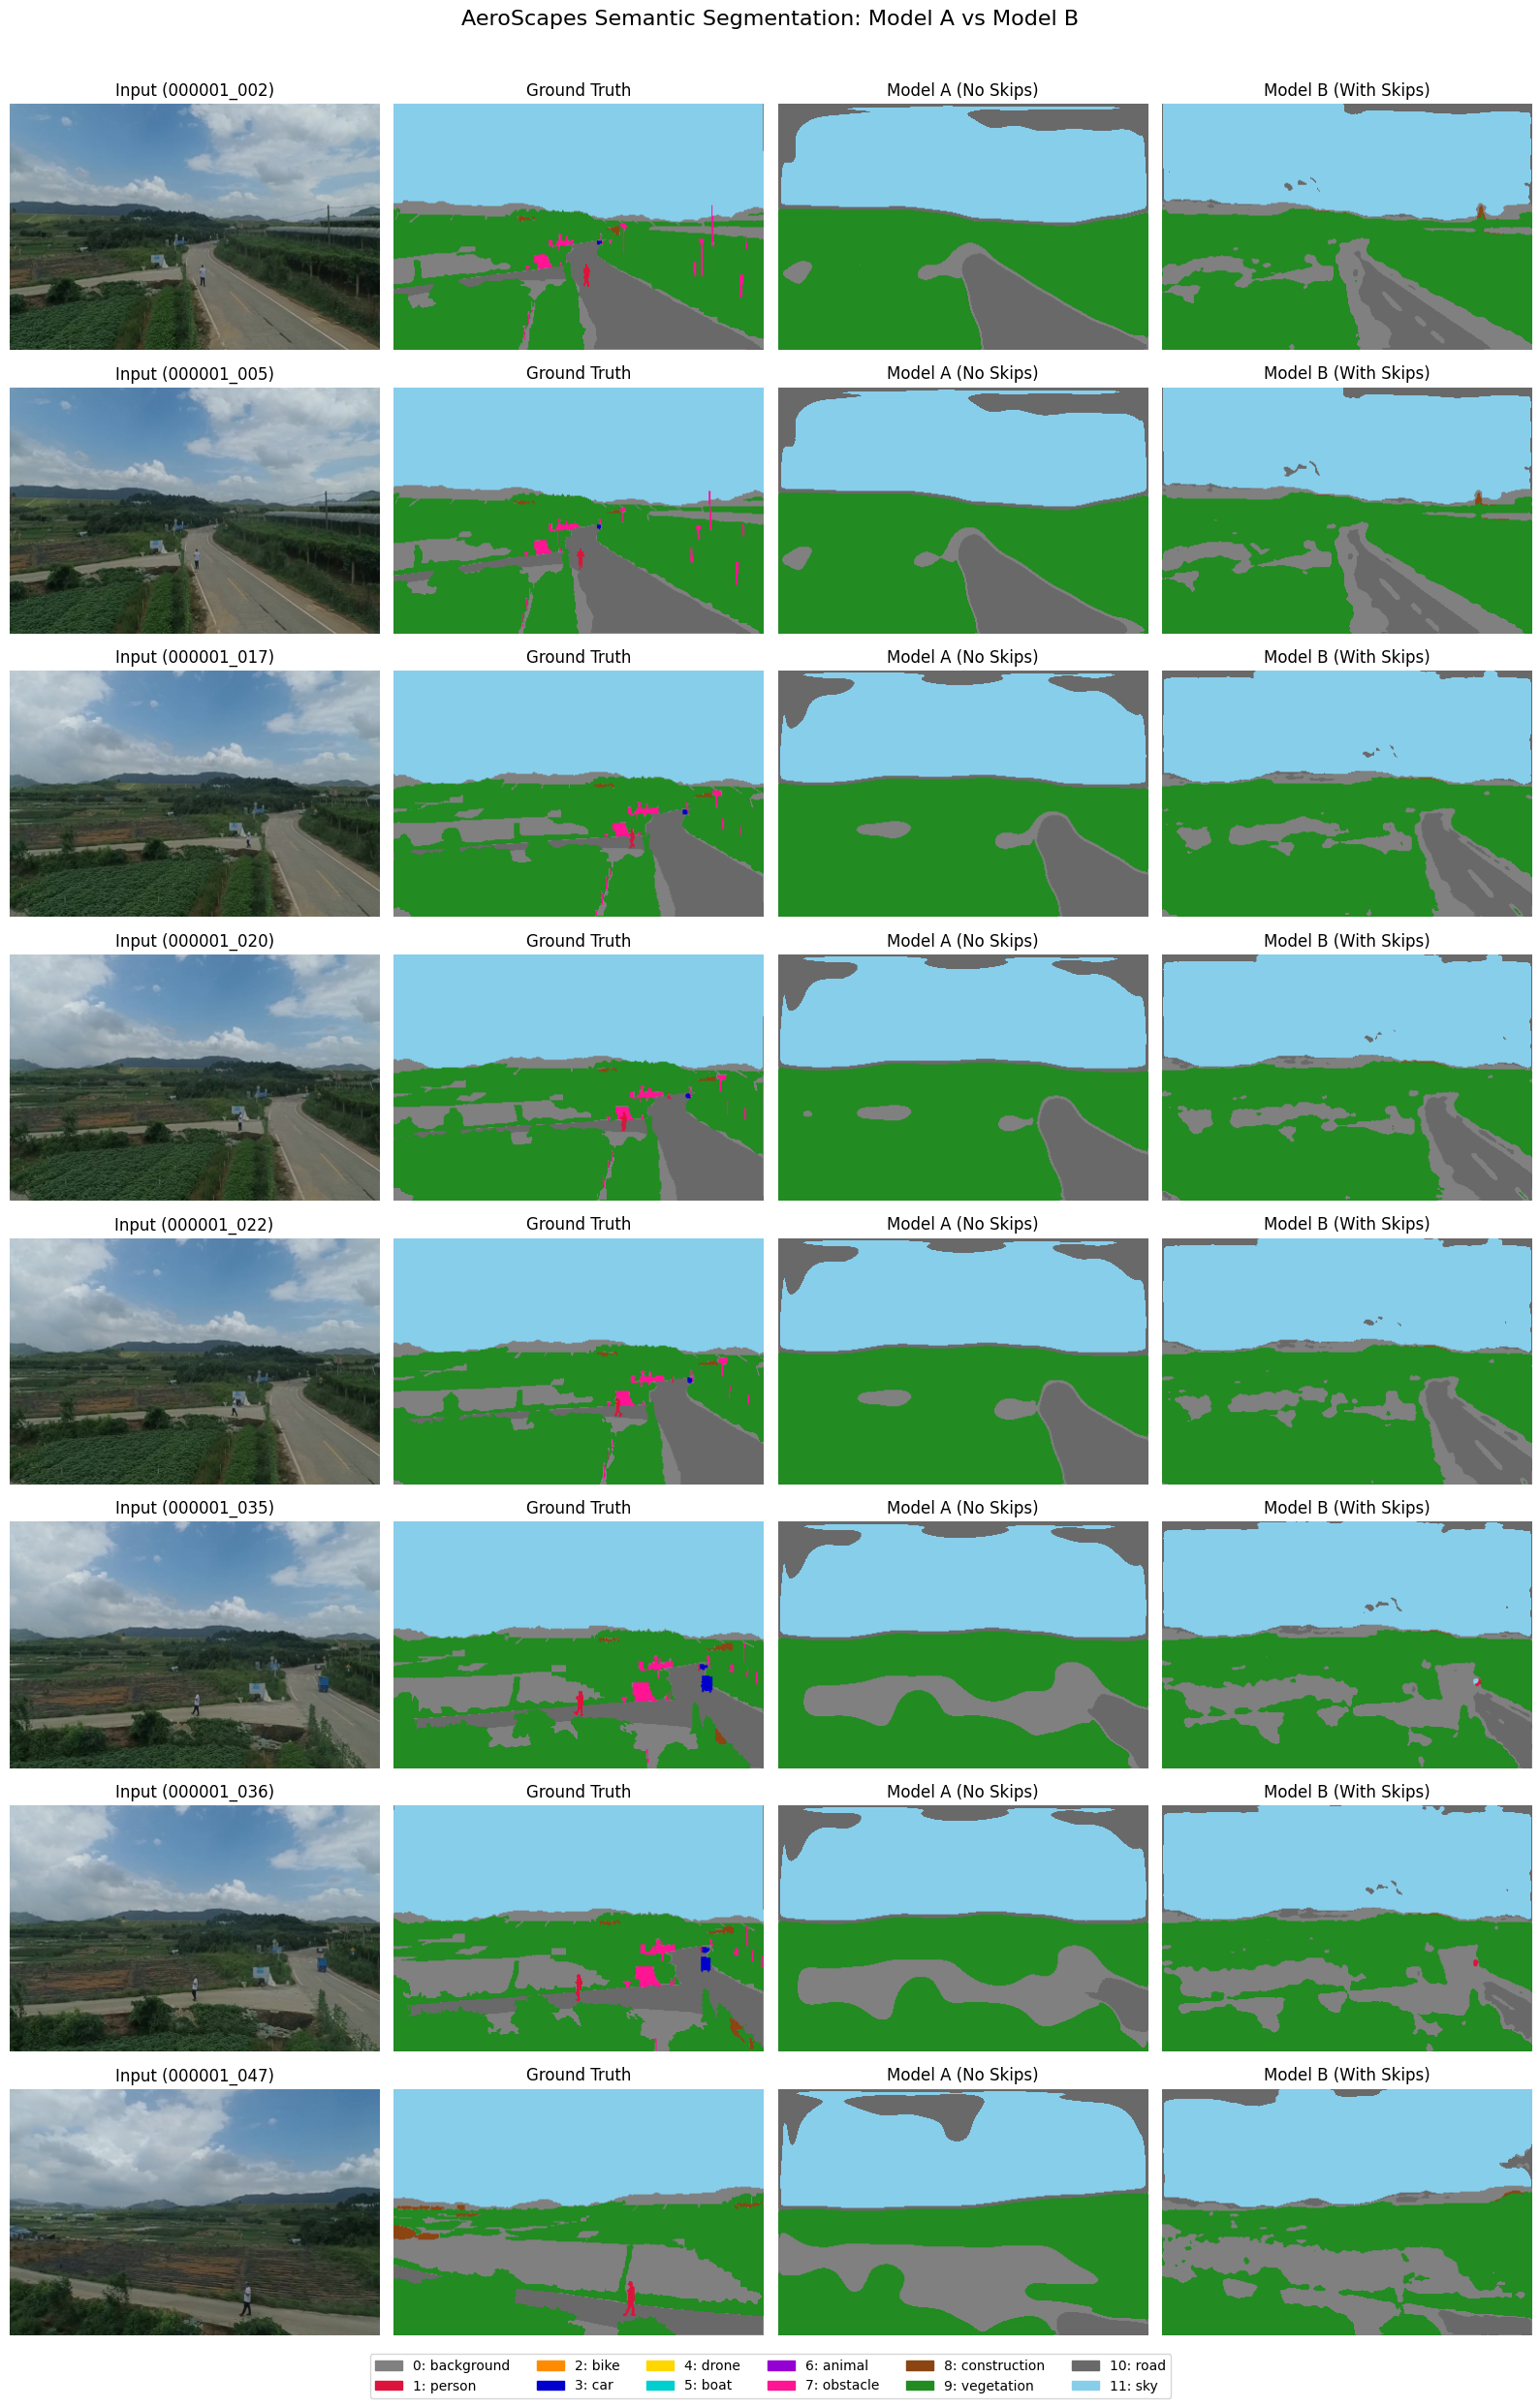

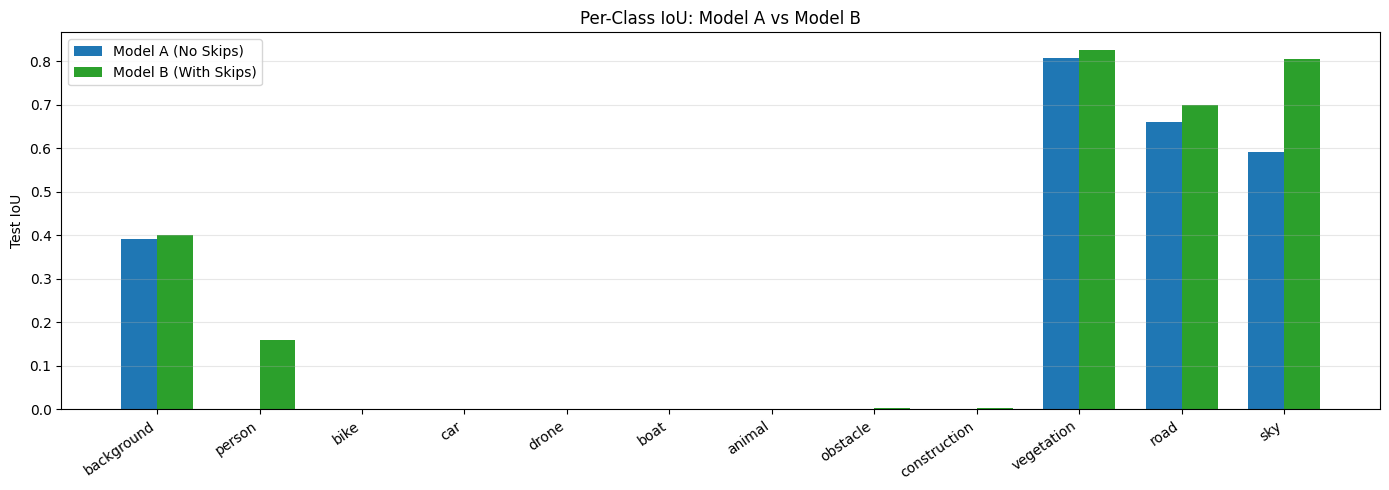

# AeroScapes Experiment Results

| Metric | Model A (No Skips) | Model B (With Skips) | Delta (B − A) |
|---|---|---|---|
| Parameters | 6,458,284 | 7,241,644 | +783,360 (+12.1%) |
| Test mIoU | 0.2042 | 0.2414 | **+0.0372** |
| Pixel Accuracy | 0.7522 | 0.7746 | +0.0223 |
| Boundary IoU | 0.1910 | 0.2072 | **+0.0162** |
| Latency (BS=1) | 9.40 ± 0.10 ms | 11.21 ± 0.15 ms | +1.82 ms |


In [22]:
# Visual Palette
PALETTE = np.array([
    [128,128,128], [220,20,60], [255,140,0], [0,0,205], [255,215,0], [0,206,209],
    [148,0,211], [255,20,147], [139,69,19], [34,139,34], [105,105,105], [135,206,235]
], dtype=np.uint8)

def colorize(m):
    rgb = np.zeros((m.shape[0], m.shape[1], 3), dtype=np.uint8)
    for i in range(12): rgb[m == i] = PALETTE[i]
    return rgb

# Qualitative Comparison Grid (8 samples)
fig, axes = plt.subplots(8, 4, figsize=(16, 24))
mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
for row in range(8):
    ra, rb = rec_a[row], rec_b[row]
    raw_img = np.clip((ra['img'] * std + mean) * 255, 0, 255).astype(np.uint8)
    axes[row, 0].imshow(raw_img); axes[row, 0].axis('off'); axes[row, 0].set_title(f"Input ({ra['id']})")
    axes[row, 1].imshow(colorize(ra['gt'])); axes[row, 1].axis('off'); axes[row, 1].set_title('Ground Truth')
    axes[row, 2].imshow(colorize(ra['pred'])); axes[row, 2].axis('off'); axes[row, 2].set_title('Model A (No Skips)')
    axes[row, 3].imshow(colorize(rb['pred'])); axes[row, 3].axis('off'); axes[row, 3].set_title('Model B (With Skips)')

patches = [mpatches.Patch(color=PALETTE[i]/255.0, label=f'{i}: {CLASS_NAMES[i]}') for i in range(12)]
fig.legend(handles=patches, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.02), fontsize=10)
plt.suptitle('AeroScapes Semantic Segmentation: Model A vs Model B', fontsize=16, y=1.01)
plt.tight_layout(); plt.savefig('results/qualitative_grid.png', bbox_inches='tight', dpi=150); plt.show()

# Per-Class IoU Bar Chart
plt.figure(figsize=(14, 5))
x = np.arange(12); w = 0.35
plt.bar(x - w/2, [0 if np.isnan(v) else v for v in ious_a], w, label='Model A (No Skips)', color='#1f77b4')
plt.bar(x + w/2, [0 if np.isnan(v) else v for v in ious_b], w, label='Model B (With Skips)', color='#2ca02c')
plt.xticks(x, CLASS_NAMES, rotation=35, ha='right')
plt.ylabel('Test IoU'); plt.title('Per-Class IoU: Model A vs Model B'); plt.legend(); plt.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig('results/per_class_iou_comparison.png'); plt.show()

# Print Markdown Summary
from IPython.display import display, Markdown
with open('results/metrics.md') as f:
    display(Markdown(f.read()))